In [1]:
import os
os.chdir("C:/Users/Admin/Desktop/Mission_Ashi")
print("Working Directory:", os.getcwd())

Working Directory: C:\Users\Admin\Desktop\Mission_Ashi


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from torch.utils.data import DataLoader, random_split
from torchvision import transforms
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
import sys
sys.path.append('utils')
from dataset import BrainTumorDataset, get_class_names

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

np.random.seed(42)
torch.manual_seed(42)

print(" Setup complete!\n")

Device: cpu
 Setup complete!



In [4]:
transform_train = transforms.Compose([
    transforms.Resize((128, 128)),  
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

transform_test = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

print(" Transforms defined!\n")

 Transforms defined!



In [5]:
data_dir = './datasets/Navoneel_binary_classification_dataset'

full_dataset = BrainTumorDataset(data_dir, transform=transform_train)

total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset_temp = random_split(
    full_dataset, [train_size, val_size, test_size]
)

test_dataset = BrainTumorDataset(data_dir, transform=transform_test)
test_indices = test_dataset_temp.indices
test_dataset = torch.utils.data.Subset(test_dataset, test_indices)

print(f"Train: {len(train_dataset)} images")
print(f"Validation: {len(val_dataset)} images")
print(f"Test: {len(test_dataset)} images\n")

Train: 125 images
Validation: 26 images
Test: 28 images



In [6]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

class_names = get_class_names(data_dir)
print(f"Classes: {class_names}\n")

Classes: ['no', 'yes']



In [7]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super(ImprovedCNN, self).__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),  
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 8 * 8, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )
    
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = ImprovedCNN().to(device)

print(f" Best model created!")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}\n")

 Best model created!
Total parameters: 8,844,418



In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

epochs = 15

history = {
    'train_loss': [],
    'val_loss': [],
    'val_acc': []
}

best_val_acc = 0.0

print(" Training setup complete!\n")

 Training setup complete!



In [9]:
print("="*60)
print("STARTING TRAINING")
print("="*60 + "\n")

for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")
    
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = train_loss / len(train_loader)
    history['train_loss'].append(avg_train_loss)
    
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    avg_val_loss = val_loss / len(val_loader)
    val_acc = val_correct / val_total
    
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)
    
    scheduler.step(avg_val_loss)
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), './models/binary_model.pth')
        save_marker = " BEST"
    else:
        save_marker = ""
    
    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f} | "
          f"Val Acc: {val_acc:.4f} {save_marker}")

print("\n" + "="*60)
print(f"TRAINING COMPLETE - Best Val Acc: {best_val_acc:.4f}")
print("="*60 + "\n")

model.load_state_dict(torch.load('./models/binary_model.pth'))
print(" Best model loaded!\n")

STARTING TRAINING



Epoch 1/15 [Train]: 100%|███████████████████████████████████████████████████| 8/8 [00:10<00:00,  1.28s/it, loss=1.5653]


Epoch 1/15 | Train Loss: 2.0961 | Val Loss: 0.9832 | Val Acc: 0.5769  BEST


Epoch 2/15 [Train]: 100%|███████████████████████████████████████████████████| 8/8 [00:09<00:00,  1.19s/it, loss=0.8782]


Epoch 2/15 | Train Loss: 1.4752 | Val Loss: 0.8031 | Val Acc: 0.5769 


...

Epoch 13/15 | Train Loss: 0.4477 | Val Loss: 0.4736 | Val Acc: 0.7308 


Epoch 14/15 [Train]: 100%|██████████████████████████████████████████████████| 8/8 [00:09<00:00,  1.20s/it, loss=0.5889]


Epoch 14/15 | Train Loss: 0.4375 | Val Loss: 0.3917 | Val Acc: 0.7308 


Epoch 15/15 [Train]: 100%|██████████████████████████████████████████████████| 8/8 [00:09<00:00,  1.21s/it, loss=0.6547]


Epoch 15/15 | Train Loss: 0.4560 | Val Loss: 0.4397 | Val Acc: 0.7308 

TRAINING COMPLETE - Best Val Acc: 0.8846

 Best model loaded!



In [10]:
model.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)

print("="*60)
print("TEST SET EVALUATION")
print("="*60)
print(f"Test Accuracy: {test_acc:.4f}\n")

print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

TEST SET EVALUATION
Test Accuracy: 0.8214

Classification Report:
              precision    recall  f1-score   support

          no       0.79      0.85      0.81        13
         yes       0.86      0.80      0.83        15

    accuracy                           0.82        28
   macro avg       0.82      0.82      0.82        28
weighted avg       0.82      0.82      0.82        28



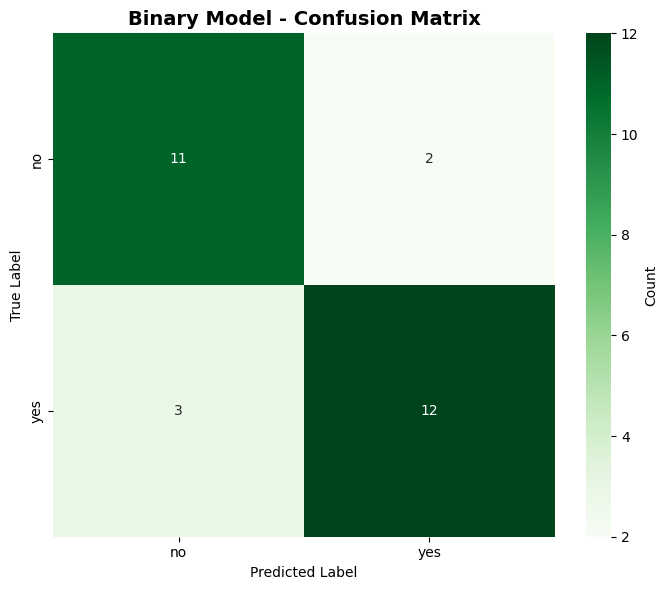

 Confusion matrix saved!



In [11]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.title('Binary Model - Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('./notebooks/binary_cm.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Confusion matrix saved!\n")

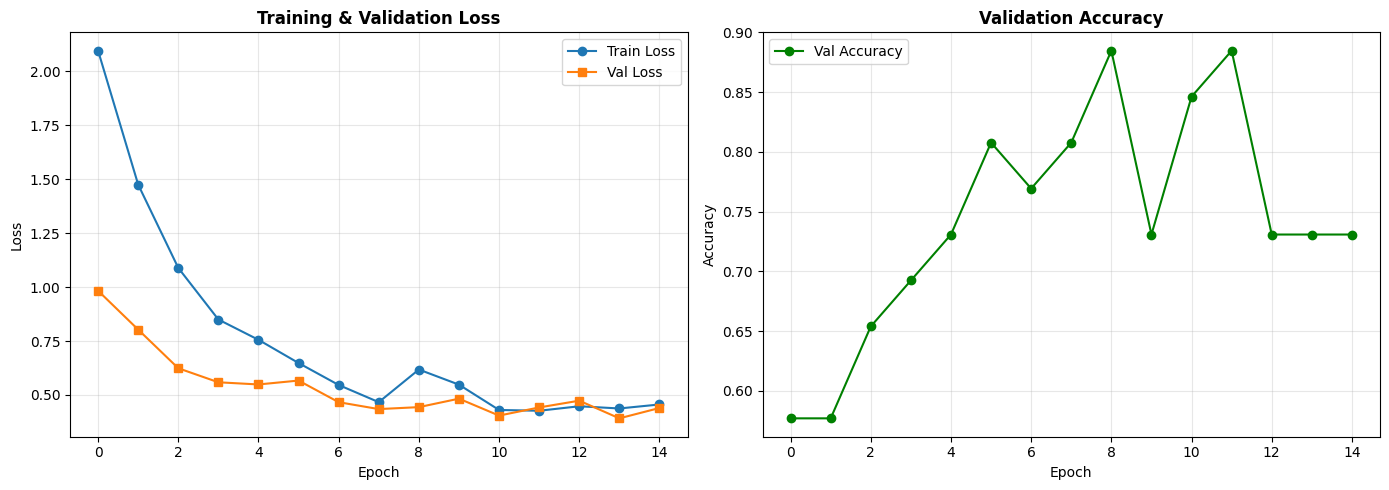

 Training history saved!



In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train Loss', marker='o')
ax1.plot(history['val_loss'], label='Val Loss', marker='s')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training & Validation Loss', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history['val_acc'], label='Val Accuracy', marker='o', color='green')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Validation Accuracy', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./notebooks/binary_training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Training history saved!\n")

In [13]:
import json

results = {
    'test_accuracy': float(test_acc),
    'best_val_accuracy': float(best_val_acc),
    'class_names': class_names,
    'total_params': sum(p.numel() for p in model.parameters()),
    'epochs_trained': epochs
}

with open('./models/binary_results.json', 'w') as f:
    json.dump(results, f, indent=4)

print("="*60)
print("NOTEBOOK 2 COMPLETE!")
print("="*60)
print(f" Model saved: ./models/binary_model.pth")
print(f" Results saved: ./models/binary_results.json")
print(f" Test Accuracy: {test_acc:.4f}")
print("="*60)

NOTEBOOK 2 COMPLETE!
 Model saved: ./models/binary_model.pth
 Results saved: ./models/binary_results.json
 Test Accuracy: 0.8214
